## Optimal Price Algorithm
**Name:** Jonathan Sutkus

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

### Single Interation

In [24]:
total_customers = 0

price = 20
outcomes = sales(price, mean_customers=100)

total_customers += len(outcomes)
revenue_per_customer = price * outcomes.mean()

print(total_customers)
print(revenue_per_customer)

81
10.617283950617285


In [ ]:
prices = np.arange(0, 70.5, 0.5) # the optimal price is between 0 and 70

In [37]:
# repeat process 1000 times at each price point to determine which price returns highest revenue per customer on average

results = []
revenue_samples = {}
total_customers = 0

for price in prices:
    revenues = []

    for repetition in range(100):
        outcomes = sales(price, mean_customers=100)

        total_customers += len(outcomes)

        revenue_per_customer = price * outcomes.mean()
        revenues.append(revenue_per_customer)

    revenue_samples[price] = revenues
    results.append((price, np.mean(revenues)))


best_price, best_revenue = max(
    results,
    key=lambda result: result[1]
)

print("Best price:", best_price)
print("Estimated revenue per customer:", best_revenue)
print("Total customers experimented with:", total_customers)

Best price: 27.5
Estimated revenue per customer: 12.066610786946887
Total customers experimented with: 1411203


In [38]:
bootstrap_best_prices = []
B = 2000

for b in range(B):
    bootstrap_results = []

    for price, revenues in revenue_samples.items():

        sampled = rng.choice(
            revenues,
            size=len(revenues),
            replace=True
        )

        bootstrap_results.append(
            (price, sampled.mean())
        )

    bootstrap_best_price, _ = max(
        bootstrap_results,
        key=lambda result: result[1]
    )

    bootstrap_best_prices.append(bootstrap_best_price)

lower = np.percentile(bootstrap_best_prices, 0.5)
upper = np.percentile(bootstrap_best_prices, 99.5)

print(f"Best price: ${best_price:.2f}")
print(f"Approximate 99% bootstrap interval: "
      f"(${lower:.2f}, ${upper:.2f})")

Best price: $27.50
Approximate 99% bootstrap interval: ($27.00, $28.50)


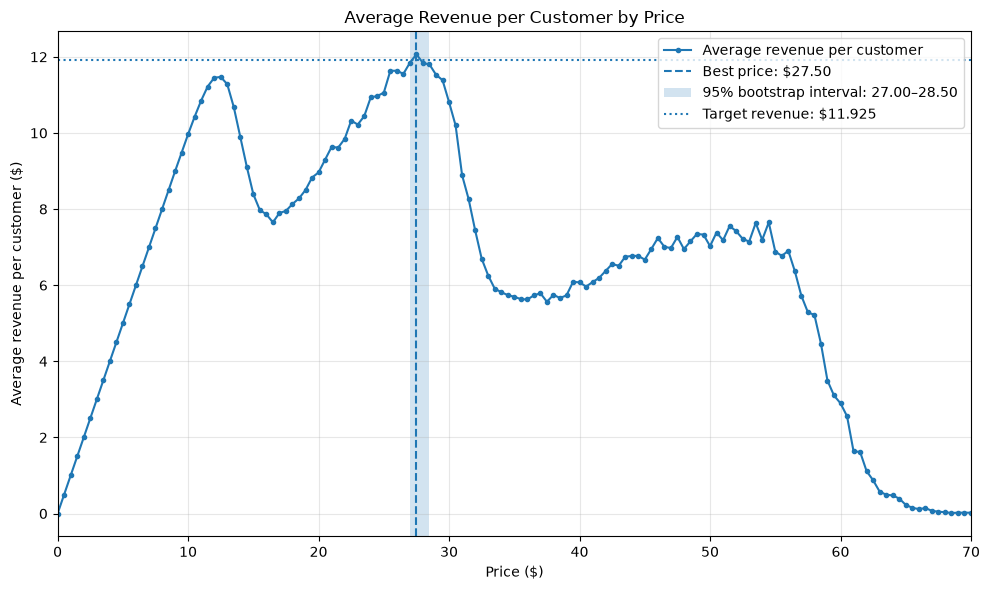

In [39]:
import matplotlib.pyplot as plt
import numpy as np

prices_plot = np.array(sorted(revenue_samples.keys()))

average_revenues = [
    np.mean(revenue_samples[p])
    for p in prices_plot
]

# Plot the results
plt.figure(figsize=(10, 6))

plt.plot(
    prices_plot,
    average_revenues,
    marker=".",
    label="Average revenue per customer"
)

plt.axvline(
    best_price,
    linestyle="--",
    label=f"Best price: ${best_price:.2f}"
)

plt.axvspan(
    lower,
    upper,
    alpha=0.2,
    label=f"95% bootstrap interval: ${lower:.2f}–${upper:.2f}"
)

plt.axhline(
    11.925,
    linestyle=":",
    label="Target revenue: $11.925"
)

plt.xlabel("Price ($)")
plt.ylabel("Average revenue per customer ($)")
plt.title("Average Revenue per Customer by Price")
plt.xlim(0, 70)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
